In [1]:
import nengo
import numpy as np
import matplotlib.pyplot as plt

# NumPy 2: nengo.Lowpass.filt() crashes on 1-D arrays. Promote them to (T, 1).
_NengoLowpass = nengo.processes.Lowpass


class Lowpass(_NengoLowpass):
    def filt(self, x, dt=None, axis=0, y0=0, copy=True, filtfilt=False):
        x = np.asarray(x)
        squeeze = x.ndim == 1
        if squeeze:
            x = x.reshape(-1, 1)
        y = super().filt(x, dt=dt, axis=axis, y0=y0, copy=copy, filtfilt=filtfilt)
        return y[:, 0] if squeeze else y


nengo.processes.Lowpass = Lowpass

# Version A: A simple dedicated circuit

Let's start with the simplest possible implementation of a system that can take 2 continuous inputs and a signal indicating which one to pay attention to.  The output should be the input that it is told to pay attention to.  

The two inputs are `stim1` and `stim2`, and the attention signal is `control`.  The output is `output`.  

For this version, we implement a completely dedicated circuit for this task.  It's a single Ensemble of 3 dimensions, combining `stim1`, `stim2` and `control` together, and then reading out the correct `stim` based on `control`.

In [2]:
model = nengo.Network()
with model:
    # Set up the inputs and outputs
    stim1 = nengo.Node(nengo.processes.WhiteSignal(high=10, period=10, seed=1))
    stim2 = nengo.Node(nengo.processes.WhiteSignal(high=10, period=10, seed=2))
    control = nengo.Node(nengo.processes.WhiteSignal(high=3, period=10, seed=3))

    output = nengo.Node(None, size_in=1)

    # build the system
    res = nengo.Ensemble(n_neurons=100, dimensions=3, radius=2)
    nengo.Connection(stim1, res[0])
    nengo.Connection(stim2, res[1])
    nengo.Connection(control, res[2], function=lambda x: -1 if x<0 else 1)
    nengo.Connection(res, output, function=lambda x: x[0] if x[2]<0 else x[1])

    # record data to plot
    p_stim1 = nengo.Probe(stim1)
    p_stim2 = nengo.Probe(stim2)
    p_control = nengo.Probe(control)
    p_output = nengo.Probe(output)
    
sim = nengo.Simulator(model)
with sim:
    sim.run(5)


HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

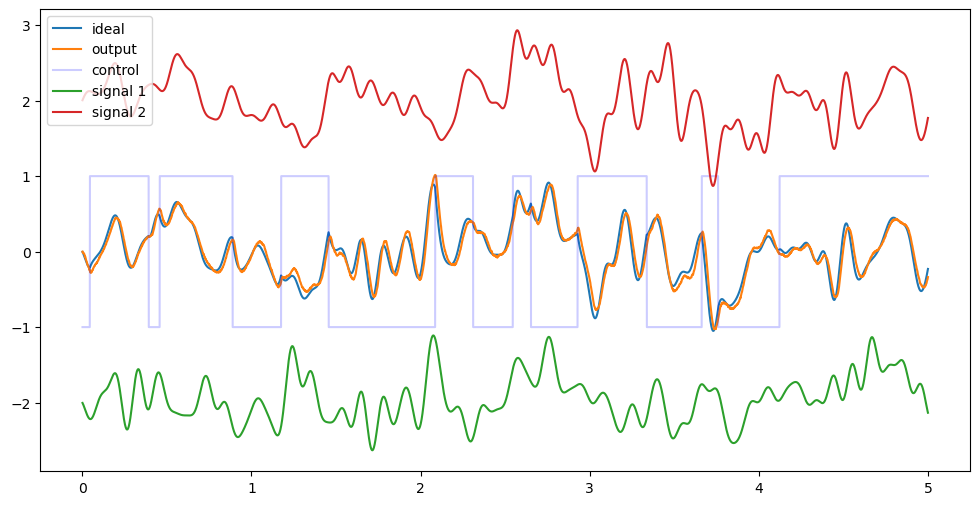

In [3]:
plt.figure(figsize=(12,6))

filt = nengo.processes.Lowpass(0.05)

ideal = np.where(sim.data[p_control]<0, sim.data[p_stim1], sim.data[p_stim2])

plt.plot(sim.trange(), filt.filt(ideal), label='ideal')
plt.plot(sim.trange(), filt.filt(sim.data[p_output]), label='output')
plt.plot(sim.trange(), np.where(sim.data[p_control]<0, -1, 1), alpha=0.2, c='b', label='control')

plt.plot(sim.trange(), filt.filt(sim.data[p_stim1])-2, label='signal 1')
plt.plot(sim.trange(), filt.filt(sim.data[p_stim2])+2, label='signal 2')
plt.legend(loc='upper left')
plt.show()

The top (black) and bottom (green) lines are the two input signals.  The blue line indicates which one of the two should be paid attention to right now. The `ideal` line is simply the correct answer, while the `output` indicates the output from the model.

One small caveat here:  I'm applying a 50ms low-pass filter to `ideal` and `output`.  The reason for this is that I'm implementing the model with spiking neurons with the default 5ms synapse.  So we're smoothing the data a little bit, and smoothing it with a time constant that is significantly larger than the internal time constant of the system.  If we wanted to be a little more careful we could handle this in other ways, but this is not too bad to start with.

In any case, this seems to work well!  The `ideal` and `output` signals are pretty similar.  However, this is a dedicated system that only does this one task.  Let's try a different implementation.

# Version B: Generic storage

Instead of having a dedicated system for this one task, let's build something a bit more generic.  In particular, let's make a workspace.  Let's have a group of neurons representing a D-dimensional vector, and we can feed the two signals into this space in their own directions.  So we randomly generate the vectors SIG1 and SIG2, and feed in the inputs as scaled values on those (`sig1*SIG1+sig2*SIG2`).   Then to read out a particular item, we just do the dot product with either `SIG1` or `SIG2`.  This generic system could then handle an arbitrary number of inputs (although here we still test it with just the 2 inputs).

In [4]:
import nengo_spa as spa
D = 128

vocab = spa.Vocabulary(D, strict=False)
SIG1 = vocab.parse('SIG1')
SIG2 = vocab.parse('SIG2')

model = nengo.Network()
with model:
    stim1 = nengo.Node(nengo.processes.WhiteSignal(high=10, period=10, seed=1))
    stim2 = nengo.Node(nengo.processes.WhiteSignal(high=10, period=10, seed=2))
    control = nengo.Node(nengo.processes.WhiteSignal(high=3, period=10, seed=3))
    output = nengo.Node(None, size_in=1)

    res = spa.State(vocab)
    
    nengo.Connection(stim1, res.input, transform=SIG1.v[:,None])
    nengo.Connection(stim2, res.input, transform=SIG2.v[:,None])

    attn = nengo.networks.Product(n_neurons=100, dimensions=D, input_magnitude=1.4/np.sqrt(D))
    nengo.Connection(control, attn.input_a, function=lambda x: SIG1.v if x[0]<0 else SIG2.v)
    nengo.Connection(res.output, attn.input_b)
    nengo.Connection(attn.output, output, transform=np.ones((1, D)))
                     

    p_stim1 = nengo.Probe(stim1)
    p_stim2 = nengo.Probe(stim2)
    p_control = nengo.Probe(control)
    p_output = nengo.Probe(output)
    
sim = nengo.Simulator(model)
with sim:
    sim.run(5)


HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

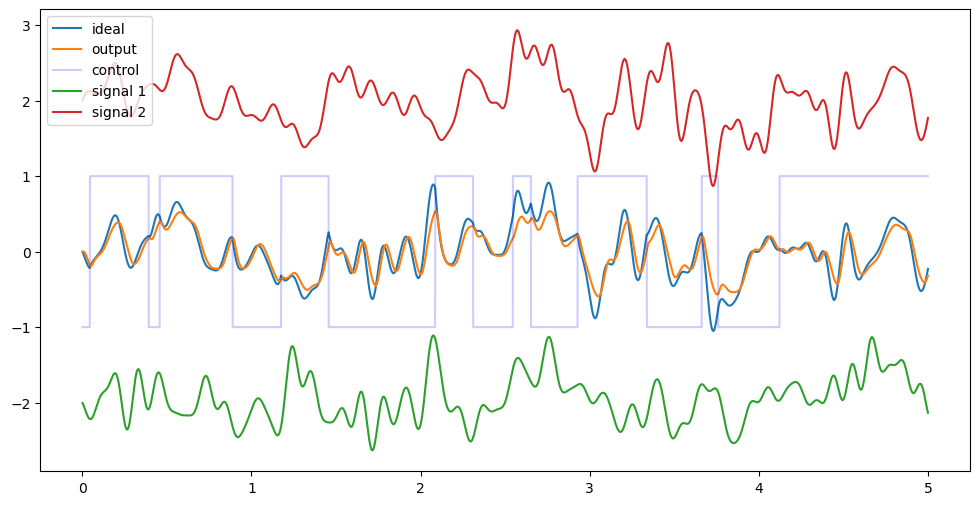

In [5]:
plt.figure(figsize=(12,6))

filt = nengo.processes.Lowpass(0.05)

ideal = np.where(sim.data[p_control]<0, sim.data[p_stim1], sim.data[p_stim2])

plt.plot(sim.trange(), filt.filt(ideal), label='ideal')
plt.plot(sim.trange(), filt.filt(sim.data[p_output]), label='output')
plt.plot(sim.trange(), np.where(sim.data[p_control]<0, -1, 1), alpha=0.2, c='b', label='control')

plt.plot(sim.trange(), filt.filt(sim.data[p_stim1])-2, label='signal 1')
plt.plot(sim.trange(), filt.filt(sim.data[p_stim2])+2, label='signal 2')
plt.legend(loc='upper left')
plt.show()

Again, it seems to work very well, and this is now a generic working memory that can encode many different things in a shared workspace, and then read out what you're interested in.

# Version C: Encoding Time

However, one thing this working memory doesn't do is have any memory of the past.  That is, it's not a reservoir in the sense of keeping information around for a while.  So, let's make a recurrent version.

In particular, I'm going to do the optimal reservoir for holding the last $\theta$ seconds of information.  The math for it is here https://papers.nips.cc/paper_files/paper/2019/hash/952285b9b7e7a1be5aa7849f32ffff05-Abstract.html but the core idea is just to take an input signal $u$ and do $\dot m = Am + Bu$.  So it's a linear differential equation, which we could implement directly or as a recurrent neural network (note that if you discretize it in time, it's $m[k+1]=A'm[k]+B'u[k]$, which just is a recurrent neural network with *linear* neurons).  One nice thing with this reservoir is that you can read out information about any point in time as just different linear weightings of `m` (so $u(t-\theta) \approx \omega_{\theta} \cdot m(t)$) 

We'll use this as a preprocessing step on the input signal, and then take the result and feed it into the same large `State` reservoir as above.  

Let's start with an efficient Nengo implementation of the LMU (also called an LDN here).  Note this could also be done in neurons, but I'm being lazy here and just doing it in math.

In [6]:
import scipy.linalg
from scipy.special import legendre

class LDN(nengo.Process):
    def __init__(self, theta, q, size_in=1):
        self.q = q              # number of internal state dimensions per input
        self.theta = theta      # size of time window (in seconds)
        self.size_in = size_in  # number of inputs

        # Do Aaron's math to generate the matrices A and B so that
        #  dx/dt = Ax + Bu will convert u into a legendre representation over a window theta
        #  https://github.com/arvoelke/nengolib/blob/master/nengolib/synapses/analog.py#L536
        A = np.zeros((q, q))
        B = np.zeros((q, 1))
        for i in range(q):
            B[i] = (-1.)**i * (2*i+1)
            for j in range(q):
                A[i,j] = (2*i+1)*(-1 if i<j else (-1.)**(i-j+1)) 
        self.A = A / theta
        self.B = B / theta        
        
        super().__init__(default_size_in=size_in, default_size_out=q*size_in)

    def make_step(self, shape_in, shape_out, dt, rng, state=None):
        state = np.zeros((self.q, self.size_in))

        # Handle the fact that we're discretizing the time step
        #  https://en.wikipedia.org/wiki/Discretization#Discretization_of_linear_state_space_models
        Ad = scipy.linalg.expm(self.A*dt)
        Bd = np.dot(np.dot(np.linalg.inv(self.A), (Ad-np.eye(self.q))), self.B)

        # this code will be called every timestep
        def step_legendre(t, x, state=state):
            state[:] = np.dot(Ad, state) + np.dot(Bd, x[None, :])
            return state.T.flatten()
        return step_legendre

    def get_weights_for_delays(self, r):
        # compute the weights needed to extract the value at time r
        # from the network (r=0 is right now, r=1 is theta seconds ago)
        r = np.asarray(r)
        m = np.asarray([legendre(i)(2*r - 1) for i in range(self.q)])
        return m.reshape(self.q, -1).T

Let's quickly make sure the LMU encoding is working on its own.  To do this, let's feed the signal into it and record `m`. Given `m` we should be able to decode the value of the input right now, and also the value of the input `theta` seconds ago, or indeed any value of time between 0 and `theta` seconds ago.  Importantly, each of these different readout values are just different linear weighted sums on the memory `m`.  And, since the LMU math has been well-characterized, we don't even need to learn these readout weights -- we can just compute them (this is what the function `get_weights_for_delays` is doing).  And yes, it turns out to just be the Legendre polynomials, which is kinda cool.

To demonstrate this, here's a quick model encoding one of the signals and then reading the value out for two different delays: a delay of 0 (i.e. the value right now) and a delay of 0.5 seconds.

Note that the accuracy of this decoding will depend on the frequency content of the signal and the number of dimensions in the LMU (`q`).  This is exactly equivalant to the question of how well you can characterize the input curve (over the last $\theta$ seconds) using `q` polynomials.

In [7]:
theta = 0.5   # amount of the past to encode in memory (in seconds)
q = 12        # dimensionality of the memory (len(m))


model = nengo.Network()
with model:
    stim1 = nengo.Node(nengo.processes.WhiteSignal(high=10, period=10, seed=1))
    ldn1 = nengo.Node(LDN(theta=theta, q=q))
    nengo.Connection(stim1, ldn1, synapse=None)

    p_stim1 = nengo.Probe(stim1)
    p_ldn1 = nengo.Probe(ldn1)

w = ldn1.output.get_weights_for_delays(r=[0,1])
sim = nengo.Simulator(model)
with sim:
    sim.run(5)



HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

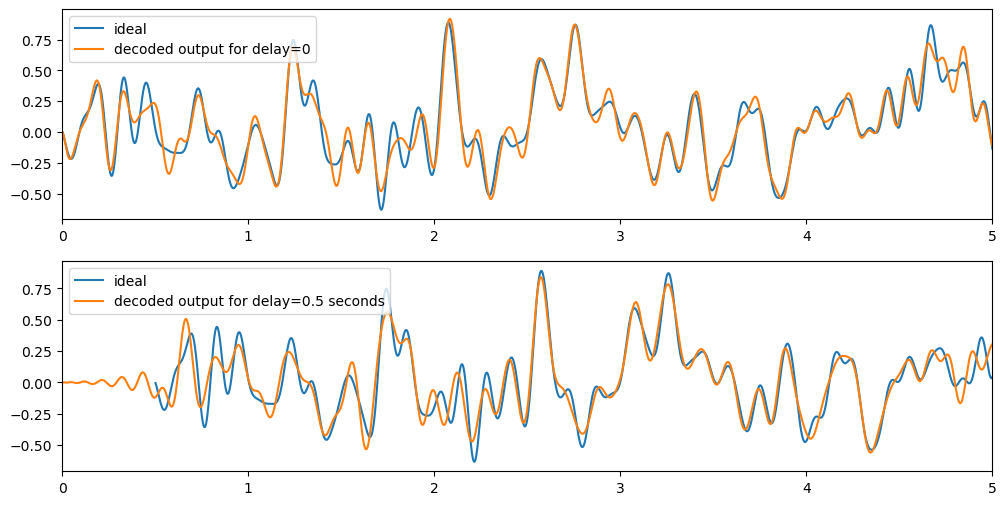

In [8]:
plt.figure(figsize=(12,6))

filt = nengo.processes.Lowpass(0.05)

plt.subplot(2, 1, 1)
plt.plot(sim.trange(), filt.filt(sim.data[p_stim1]), label='ideal')
plt.plot(sim.trange(), filt.filt(np.dot(sim.data[p_ldn1], w[0])[:, None]), label='decoded output for delay=0')
plt.legend()
plt.xlim(0, 5)
plt.subplot(2, 1, 2)
plt.plot(sim.trange()+theta, filt.filt(sim.data[p_stim1]), label='ideal')
plt.plot(sim.trange(), filt.filt(np.dot(sim.data[p_ldn1], w[1])[:, None]), label=f'decoded output for delay={theta} seconds')
plt.legend()
plt.xlim(0, 5)
plt.show()



This is doing a pretty good job.  We could make it better by increasing `q` (or decreasing `theta`, or decreasing the maximum frequency of the input) if we wanted to.

But, let's combine the `m` values for both signals all into our reservoir and then decode out what we wanted.  Let's start by just simulating the reservoir and then showing that we can decode either SIG1 or SIG2 and at different points in time in the past.

In [9]:
import nengo_spa as spa
D = 512
theta = 0.5   # amount of the past to encode in memory (in seconds)
q = 12        # dimensionality of the memory (len(m))

vocab = spa.Vocabulary(D, strict=False)
vocab.populate('SIG1.unitary()')
vocab.populate('SIG2.unitary()')
vocab.populate('M.unitary()')

SIG1 = vocab.parse('SIG1')
SIG2 = vocab.parse('SIG2')
M = vocab.parse('M')
M = np.array([(M**i).v for i in range(q)])


model = nengo.Network()
with model:
    stim1 = nengo.Node(nengo.processes.WhiteSignal(high=10, period=10, seed=1))
    ldn1 = nengo.Node(LDN(theta=theta, q=q))
    nengo.Connection(stim1, ldn1, synapse=None)
    
    stim2 = nengo.Node(nengo.processes.WhiteSignal(high=10, period=10, seed=2))
    ldn2 = nengo.Node(LDN(theta=theta, q=q))
    nengo.Connection(stim2, ldn2, synapse=None)
    
    control = nengo.Node(nengo.processes.WhiteSignal(high=3, period=10, seed=3))
    output = nengo.Node(None, size_in=1)

    res = spa.State(vocab, represent_cc_identity=False)
    nengo.Connection(ldn1, res.input, transform=np.dot(M, SIG1.get_binding_matrix()).T)
    nengo.Connection(ldn2, res.input, transform=np.dot(M, SIG2.get_binding_matrix()).T)


    p_stim1 = nengo.Probe(stim1)
    p_stim2 = nengo.Probe(stim2)
    p_control = nengo.Probe(control)
    #p_output = nengo.Probe(output)
    p_res = nengo.Probe(res.output)
    
sim = nengo.Simulator(model)
with sim:
    sim.run(5)


HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

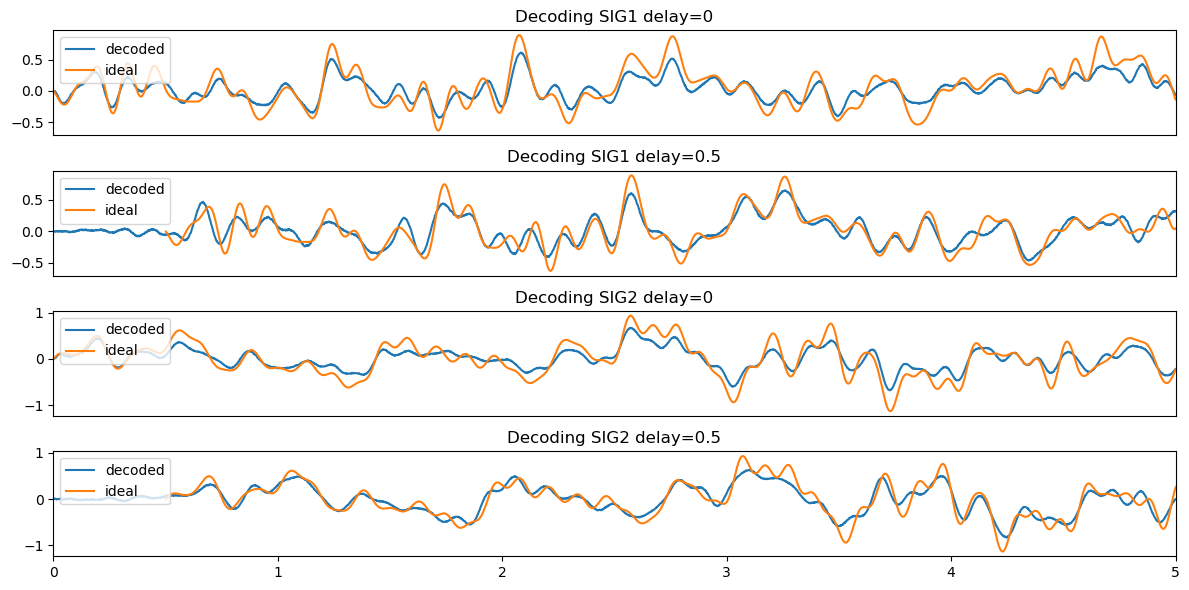

In [10]:
plt.figure(figsize=(12,6))

filt = nengo.processes.Lowpass(0.05)

r = filt.filt(sim.data[p_res])

plt.subplot(4, 1, 1)
plt.plot(sim.trange(), r.dot((~SIG1).get_binding_matrix()).dot(np.dot(w[0], M)), label='decoded')
plt.plot(sim.trange(), filt.filt(sim.data[p_stim1]), label='ideal')
plt.legend(loc='upper left')
plt.title('Decoding SIG1 delay=0')
plt.xticks([])
plt.xlim(0, 5)

plt.subplot(4, 1, 2)
plt.plot(sim.trange(), r.dot((~SIG1).get_binding_matrix()).dot(np.dot(w[1], M)), label='decoded')
plt.plot(sim.trange()+theta, filt.filt(sim.data[p_stim1]), label='ideal')
plt.title(f'Decoding SIG1 delay={theta}')
plt.legend(loc='upper left')
plt.xticks([])
plt.xlim(0, 5)

plt.subplot(4, 1, 3)
plt.plot(sim.trange(), r.dot((~SIG2).get_binding_matrix()).dot(np.dot(w[0], M)), label='decoded')
plt.plot(sim.trange(), filt.filt(sim.data[p_stim2]), label='ideal')
plt.legend(loc='upper left')
plt.title('Decoding SIG2 delay=0')
plt.xticks([])
plt.xlim(0, 5)

plt.subplot(4, 1, 4)
plt.plot(sim.trange(), r.dot((~SIG2).get_binding_matrix()).dot(np.dot(w[1], M)), label='decoded')
plt.plot(sim.trange()+theta, filt.filt(sim.data[p_stim2]), label='ideal')
plt.title(f'Decoding SIG2 delay={theta}')
plt.legend(loc='upper left')
plt.xlim(0, 5)

plt.tight_layout()
plt.show()

That works pretty good!  So we know the information is in the reservoir.  Now let's have the system decode out the correct information while the model is running.  We do this by setting up an "attention" network (similar to the dot product network in the above example).  By feeding in different inputs, we can tell the network to pay attention to either the left or right signal, and at what point in time in the past to pay attention to.

While I wrote it as a dot product in the above example, here I'm doing it as the equivalent Cicular Convolution calculation.  There's no real difference here, other than this would also handle more generic cases where there's lots of different information we wanted to pull out of the memory, rather than just one thing.

Also, for efficiency reasons I'm not doing the circular convolution in neurons, but we've shown lots of times in other places that we can do that calculation in neurons.  But for this work we're more interested in the reservoir rather than how the brain does the readout, so I figured it was less important here.

In [11]:
model = nengo.Network()
with model:
    stim1 = nengo.Node(nengo.processes.WhiteSignal(high=10, period=10, seed=1))
    ldn1 = nengo.Node(LDN(theta=theta, q=q))
    nengo.Connection(stim1, ldn1, synapse=None)
    
    stim2 = nengo.Node(nengo.processes.WhiteSignal(high=10, period=10, seed=2))
    ldn2 = nengo.Node(LDN(theta=theta, q=q))
    nengo.Connection(stim2, ldn2, synapse=None)
    
    control = nengo.Node(nengo.processes.WhiteSignal(high=3, period=10, seed=3))
    output = nengo.Node(None, size_in=1)

    res = spa.State(vocab, represent_cc_identity=False)
    nengo.Connection(ldn1, res.input, transform=np.dot(M, SIG1.get_binding_matrix()).T)
    nengo.Connection(ldn2, res.input, transform=np.dot(M, SIG2.get_binding_matrix()).T)

    attn = nengo.Node(lambda t,x: vocab.algebra.bind(x[:D], vocab.algebra.invert(x[D:])), size_in=D*2, size_out=D)
    
    nengo.Connection(res.output, attn[:D], synapse=None)
    ATTN1 = vocab.algebra.bind((~SIG1).v, np.dot(w[0], M))
    ATTN2 = vocab.algebra.bind((~SIG2).v, np.dot(w[0], M))
    nengo.Connection(control, attn[D:], function=lambda x: ATTN1 if x[0]<0 else ATTN2, synapse=None)
    nengo.Connection(attn[0], output, synapse=None)
                         
    p_stim1 = nengo.Probe(stim1)
    p_stim2 = nengo.Probe(stim2)
    p_control = nengo.Probe(control)
    p_output = nengo.Probe(output)
    p_res = nengo.Probe(res.output)

    
sim = nengo.Simulator(model, optimize=False)
with sim:
    sim.run(5)


HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

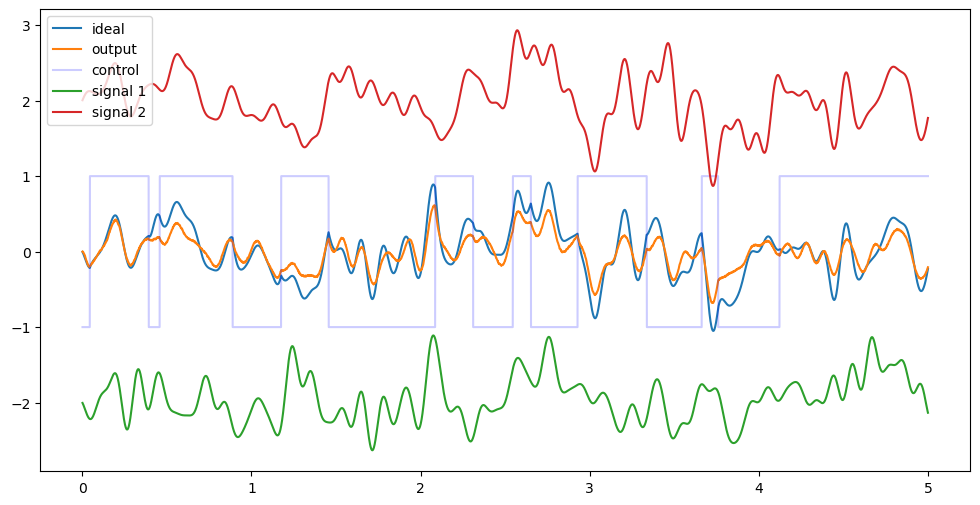

In [12]:
plt.figure(figsize=(12,6))

filt = nengo.processes.Lowpass(0.05)

ideal = np.where(sim.data[p_control]<0, sim.data[p_stim1], sim.data[p_stim2])

plt.plot(sim.trange(), filt.filt(ideal), label='ideal')
plt.plot(sim.trange(), filt.filt(sim.data[p_output]), label='output')
plt.plot(sim.trange(), np.where(sim.data[p_control]<0, -1, 1), alpha=0.2, c='b', label='control')

plt.plot(sim.trange(), filt.filt(sim.data[p_stim1])-2, label='signal 1')
plt.plot(sim.trange(), filt.filt(sim.data[p_stim2])+2, label='signal 2')
plt.legend(loc='upper left')
plt.show()

It works!

So that's three different ways of implementing this reservoir.  One thing that I should probably add is that instead of taking the output from the LDN and feeding it into the State neurons, we could also skip the LDN and implement it in a recurrent connection on the State neurons.  This should be equivalent, given sufficient neurons in the State population.

Next we replace the reservoir in **each** of those three versions with the same spin-QRC, and compare each pair separately.  A, B, and C are doing different jobs (dedicated switch, shared workspace + query, delay line + workspace), so a QRC that is fair for one is not automatically fair for the others.


# Replacing the reservoir with a quantum one (4 qubits, exact expectations)

Now we swap the neural reservoir in each of A, B and C for a **4-qubit quantum reservoir** and change nothing else: same inputs, same attention signal, same target.  In every cell below the classical reservoir and the quantum one sit side by side in one network, driven by the same nodes.

The quantum reservoir is a 4-qubit spin-QRC with a fixed, random, untrained Hamiltonian

$$\hat H=\sum_{i<j} J_{ij}\,\hat\sigma^x_i\hat\sigma^x_j + h\sum_i\hat\sigma^z_i,\qquad J_{ij}\sim U(-1,1),\ h=1.$$

Every timestep, each input value $u$ is written into qubit 0 by resetting it to $|\psi(s)\rangle=\sqrt{1-s}\,|0\rangle+\sqrt{s}\,|1\rangle$ with $s=0.25u+0.5$ (the attention bit uses $s\in\{0,1\}$), while the other 3 qubits carry the memory forward via the partial trace $\operatorname{Tr}_0(\hat\rho)$.  The register then evolves unitarily under $U=e^{-i\hat H\tau}$ ($\tau=3$), with **no dissipation and no dephasing**.  The reservoir's output is the 10 exact expectation values $\langle Z_i\rangle$ (4 values) and $\langle Z_iZ_j\rangle$ (6 pairs).

A linear readout on those 10 features is trained by ridge regression on 0.5–3 s and tested on 3–5 s.

In [13]:
from scipy.linalg import expm
import nengo_spa as spa


class QuantumReservoir(nengo.Process):
    """4-qubit spin-QRC: reset input on qubit 0 + unitary evolution U = exp(-i H tau).

    No dissipation and no dephasing. Output is the exact expectation values <Z_i> and <Z_i Z_j>.
    `cue_index` marks a binary input channel (sign -> 0/1).
    """

    def __init__(self, size_in, n_qubits=4, J_s=1.0, h=1.0, tau=3.0, cue_index=None, seed=0):
        n = self.n = n_qubits
        self.cue_index = cue_index
        rng = np.random.default_rng(seed)
        X, Z = np.array([[0, 1], [1, 0]]), np.diag([1.0, -1.0])
        op = lambda o, i: np.kron(np.kron(np.eye(2**i), o), np.eye(2**(n-1-i)))
        H = sum(rng.uniform(-J_s, J_s) * op(X, i) @ op(X, j)
                for i in range(n) for j in range(i + 1, n))
        H = H + h * sum(op(Z, i) for i in range(n))
        self.U = expm(-1j * tau * H)
        bits = (np.arange(2**n)[:, None] >> (n - 1 - np.arange(n))) & 1
        self.Zb = 1 - 2 * bits                      # Zb[b, i] = <b|Z_i|b>
        self.pairs = np.triu_indices(n, 1)
        super().__init__(default_size_in=size_in, default_size_out=n + len(self.pairs[0]))

    def make_step(self, shape_in, shape_out, dt, rng, state=None):
        n, U, Ud, D = self.n, self.U, self.U.conj().T, 2**(self.n - 1)
        rho = np.zeros((2**n, 2**n), dtype=complex)
        rho[0, 0] = 1
        state = [rho]

        def step(t, x):
            rho = state[0]
            for k, u in enumerate(x):
                s = float(u > 0) if k == self.cue_index else np.clip(0.25 * u + 0.5, 0, 1)
                psi = np.array([np.sqrt(1 - s), np.sqrt(s)])
                rest = np.einsum("ajak->jk", rho.reshape(2, D, 2, D))
                rho = U @ np.kron(np.outer(psi, psi), rest) @ Ud
            state[0] = rho
            P = rho.diagonal().real
            return np.concatenate([P @ self.Zb, ((self.Zb.T * P) @ self.Zb)[self.pairs]])

        return step


train, test = slice(500, 3000), slice(3000, None)     # 0.5-3 s train, 3-5 s test (dt = 1 ms)
filt = nengo.processes.Lowpass(0.05)


def train_readout(X, y, l2=1e-3):
    """Ridge readout fit on the training window; returns the prediction over the whole run."""
    Xb = np.column_stack([X, np.ones(len(X))])
    y = np.asarray(y).reshape(-1)
    w = np.linalg.solve(Xb[train].T @ Xb[train] + l2 * np.eye(Xb.shape[1]), Xb[train].T @ y[train])
    return Xb @ w


def nmse(ideal, output):
    """Test-window (3-5 s) error after the 50 ms low-pass used in the plots; 0 is perfect, 1 is chance."""
    a, b = filt.filt(np.ravel(ideal)), filt.filt(np.ravel(output))
    return float(np.mean((a[test] - b[test]) ** 2) / np.var(a[test]))


def plot_compare(t, s1, s2, ctrl, ideal, outputs, title):
    plt.figure(figsize=(12, 6))
    plt.plot(t, filt.filt(np.ravel(ideal)), "k", lw=2, label="ideal")
    for name, y in outputs.items():
        plt.plot(t, filt.filt(np.ravel(y)), label=f"{name}   (test NMSE {nmse(ideal, y):.3f})")
    plt.plot(t, np.where(ctrl < 0, -1, 1), alpha=0.2, c="b", label="control")
    plt.plot(t, filt.filt(np.ravel(s1)) - 2, label="signal 1")
    plt.plot(t, filt.filt(np.ravel(s2)) + 2, label="signal 2")
    plt.axvline(3.0, c="gray", ls=":")
    plt.text(3.02, 2.9, "test", color="gray")
    plt.legend(loc="upper left")
    plt.title(title)
    plt.show()


scores = {}

## A-QRC: replace the 3-D ensemble

Version A's reservoir is one 3-D ensemble holding `(stim1, stim2, control)`.  The 4-qubit quantum reservoir gets the same three inputs (three resets per timestep), and a single linear readout is trained on the attended signal.  Like A, it has to do the selection itself: the control is inside the reservoir, not a switch on the output.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

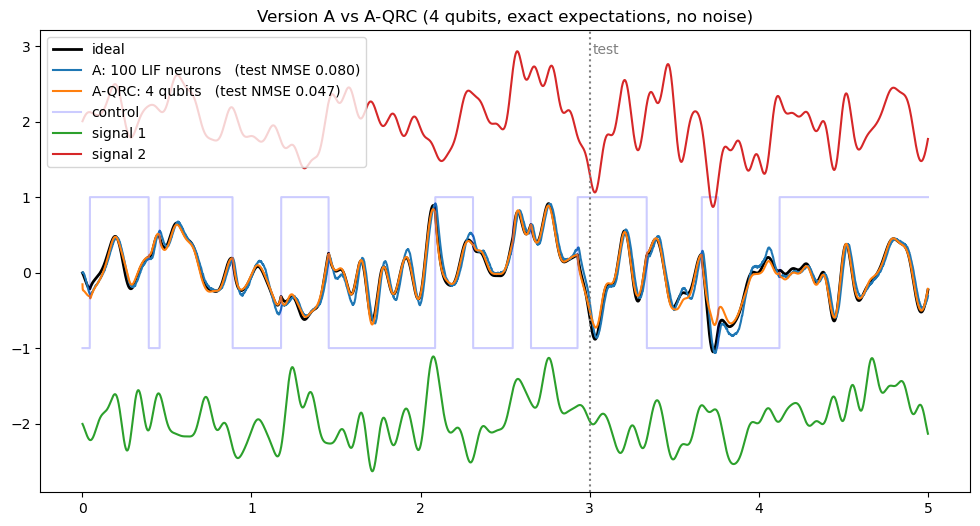

In [14]:
model = nengo.Network()
with model:
    stim1 = nengo.Node(nengo.processes.WhiteSignal(high=10, period=10, seed=1))
    stim2 = nengo.Node(nengo.processes.WhiteSignal(high=10, period=10, seed=2))
    control = nengo.Node(nengo.processes.WhiteSignal(high=3, period=10, seed=3))

    # classical reservoir (Version A)
    res = nengo.Ensemble(n_neurons=100, dimensions=3, radius=2)
    nengo.Connection(stim1, res[0])
    nengo.Connection(stim2, res[1])
    nengo.Connection(control, res[2], function=lambda x: -1 if x<0 else 1)
    output = nengo.Node(None, size_in=1)
    nengo.Connection(res, output, function=lambda x: x[0] if x[2]<0 else x[1])

    # 4-qubit quantum reservoir, same inputs
    qres = nengo.Node(QuantumReservoir(size_in=3, n_qubits=4, cue_index=2))
    nengo.Connection(stim1, qres[0], synapse=None)
    nengo.Connection(stim2, qres[1], synapse=None)
    nengo.Connection(control, qres[2], function=lambda x: -1 if x<0 else 1, synapse=None)

    p_stim1, p_stim2, p_control = nengo.Probe(stim1), nengo.Probe(stim2), nengo.Probe(control)
    p_output, p_qres = nengo.Probe(output), nengo.Probe(qres)

sim = nengo.Simulator(model)
with sim:
    sim.run(5)

ideal = np.where(sim.data[p_control]<0, sim.data[p_stim1], sim.data[p_stim2])
q_output = train_readout(sim.data[p_qres], ideal)
scores["A"] = (nmse(ideal, sim.data[p_output]), nmse(ideal, q_output))
plot_compare(sim.trange(), sim.data[p_stim1], sim.data[p_stim2], sim.data[p_control], ideal,
             {"A: 100 LIF neurons": sim.data[p_output], "A-QRC: 4 qubits": q_output},
             "Version A vs A-QRC (4 qubits, exact expectations, no noise)")

## B-QRC: replace the SPA workspace

Version B stores both signals in a shared `State` and reads one out with a query (dot product with `SIG1` or `SIG2`).  The 4-qubit quantum reservoir gets only the two signals.  Its query is two linear readouts on the same 10 numbers, one trained to recover signal 1 and one signal 2, with the control choosing between them, just as the control chooses `SIG1` or `SIG2` in B.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

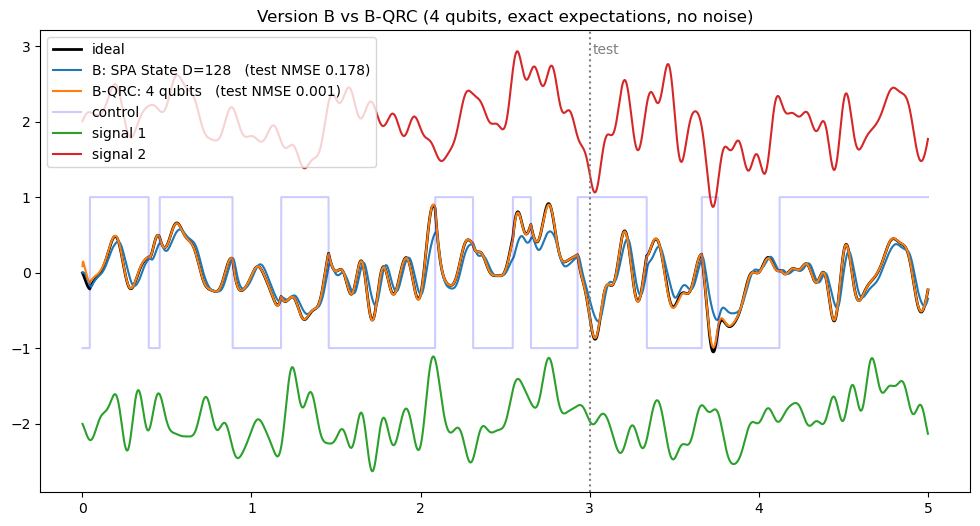

In [15]:
D = 128
vocab = spa.Vocabulary(D, strict=False)
SIG1 = vocab.parse('SIG1')
SIG2 = vocab.parse('SIG2')

model = nengo.Network()
with model:
    stim1 = nengo.Node(nengo.processes.WhiteSignal(high=10, period=10, seed=1))
    stim2 = nengo.Node(nengo.processes.WhiteSignal(high=10, period=10, seed=2))
    control = nengo.Node(nengo.processes.WhiteSignal(high=3, period=10, seed=3))

    # classical reservoir (Version B)
    res = spa.State(vocab)
    nengo.Connection(stim1, res.input, transform=SIG1.v[:,None])
    nengo.Connection(stim2, res.input, transform=SIG2.v[:,None])
    attn = nengo.networks.Product(n_neurons=100, dimensions=D, input_magnitude=1.4/np.sqrt(D))
    nengo.Connection(control, attn.input_a, function=lambda x: SIG1.v if x[0]<0 else SIG2.v)
    nengo.Connection(res.output, attn.input_b)
    output = nengo.Node(None, size_in=1)
    nengo.Connection(attn.output, output, transform=np.ones((1, D)))

    # 4-qubit quantum reservoir, same two signals
    qres = nengo.Node(QuantumReservoir(size_in=2, n_qubits=4))
    nengo.Connection(stim1, qres[0], synapse=None)
    nengo.Connection(stim2, qres[1], synapse=None)

    p_stim1, p_stim2, p_control = nengo.Probe(stim1), nengo.Probe(stim2), nengo.Probe(control)
    p_output, p_qres = nengo.Probe(output), nengo.Probe(qres)

sim = nengo.Simulator(model)
with sim:
    sim.run(5)

ideal = np.where(sim.data[p_control]<0, sim.data[p_stim1], sim.data[p_stim2])
X, ctrl = sim.data[p_qres], sim.data[p_control][:, 0]
q_output = np.where(ctrl<0, train_readout(X, sim.data[p_stim1]), train_readout(X, sim.data[p_stim2]))
scores["B"] = (nmse(ideal, sim.data[p_output]), nmse(ideal, q_output))
plot_compare(sim.trange(), sim.data[p_stim1], sim.data[p_stim2], sim.data[p_control], ideal,
             {"B: SPA State D=128": sim.data[p_output], "B-QRC: 4 qubits": q_output},
             "Version B vs B-QRC (4 qubits, exact expectations, no noise)")

## C-QRC: replace the `State` behind the LDN

Version C puts an LDN (the optimal $\theta$-second memory) in front of the `State` and unbinds the signal at a chosen delay.  We keep the same two LDNs and replace only the `State`.  Four qubits cannot hold all $2\times12$ LDN dimensions, so each LDN is decoded to the two values the task asks for, its value now ($r=0$) and $\theta$ ago ($r=1$), and those four numbers are written into qubit 0 each timestep.  The readout works as in B, with one map per signal and delay.

Both versions are queried at delay 0 (Version C's running model) and at delay $\theta=0.5$ s (what the LDN is there for).

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

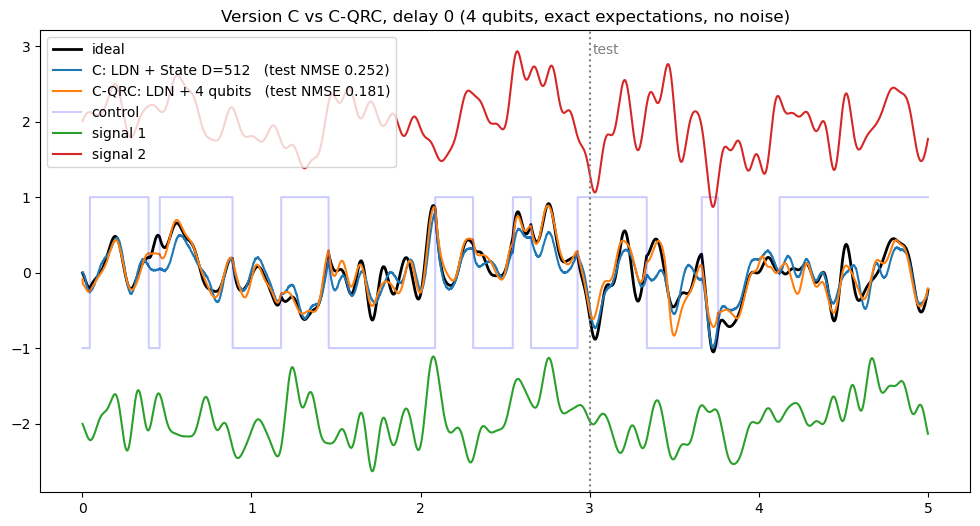

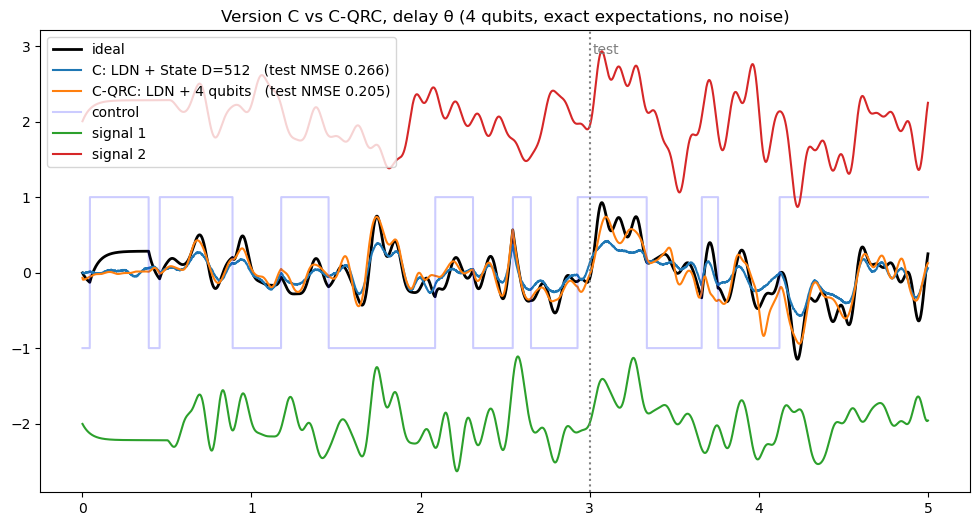

In [16]:
D = 512
theta = 0.5
q = 12
vocab = spa.Vocabulary(D, strict=False)
vocab.populate('SIG1.unitary()')
vocab.populate('SIG2.unitary()')
vocab.populate('M.unitary()')
SIG1 = vocab.parse('SIG1')
SIG2 = vocab.parse('SIG2')
M = vocab.parse('M')
M = np.array([(M**i).v for i in range(q)])
w = LDN(theta=theta, q=q).get_weights_for_delays(r=[0, 1])

model = nengo.Network()
with model:
    stim1 = nengo.Node(nengo.processes.WhiteSignal(high=10, period=10, seed=1))
    stim2 = nengo.Node(nengo.processes.WhiteSignal(high=10, period=10, seed=2))
    control = nengo.Node(nengo.processes.WhiteSignal(high=3, period=10, seed=3))
    ldn1 = nengo.Node(LDN(theta=theta, q=q))
    ldn2 = nengo.Node(LDN(theta=theta, q=q))
    nengo.Connection(stim1, ldn1, synapse=None)
    nengo.Connection(stim2, ldn2, synapse=None)

    # classical reservoir (Version C), queried at delay 0 and delay theta
    res = spa.State(vocab, represent_cc_identity=False)
    nengo.Connection(ldn1, res.input, transform=np.dot(M, SIG1.get_binding_matrix()).T)
    nengo.Connection(ldn2, res.input, transform=np.dot(M, SIG2.get_binding_matrix()).T)
    p_output = []
    for r in range(2):
        attn = nengo.Node(lambda t,x: vocab.algebra.bind(x[:D], vocab.algebra.invert(x[D:])), size_in=D*2, size_out=D)
        nengo.Connection(res.output, attn[:D], synapse=None)
        ATTN1 = vocab.algebra.bind((~SIG1).v, np.dot(w[r], M))
        ATTN2 = vocab.algebra.bind((~SIG2).v, np.dot(w[r], M))
        nengo.Connection(control, attn[D:], function=lambda x, a1=ATTN1, a2=ATTN2: a1 if x[0]<0 else a2, synapse=None)
        output = nengo.Node(None, size_in=1)
        nengo.Connection(attn[0], output, synapse=None)
        p_output.append(nengo.Probe(output))

    # 4-qubit quantum reservoir behind the same LDNs: (signal 1 now, theta ago, signal 2 now, theta ago)
    qres = nengo.Node(QuantumReservoir(size_in=4, n_qubits=4))
    nengo.Connection(ldn1, qres[0:2], transform=w, synapse=None)
    nengo.Connection(ldn2, qres[2:4], transform=w, synapse=None)

    p_stim1, p_stim2, p_control = nengo.Probe(stim1), nengo.Probe(stim2), nengo.Probe(control)
    p_qres = nengo.Probe(qres)

sim = nengo.Simulator(model, optimize=False)
with sim:
    sim.run(5)

d = int(theta / 0.001)
X, ctrl = sim.data[p_qres], sim.data[p_control][:, 0]
for r, label in ((0, "delay 0"), (1, "delay θ")):
    s1, s2 = sim.data[p_stim1][:, 0], sim.data[p_stim2][:, 0]
    if r == 1:                                   # the signals theta seconds ago
        s1 = np.concatenate([np.full(d, s1[0]), s1[:-d]])
        s2 = np.concatenate([np.full(d, s2[0]), s2[:-d]])
    ideal = np.where(ctrl<0, s1, s2)
    q_output = np.where(ctrl<0, train_readout(X, s1), train_readout(X, s2))
    scores[f"C, {label}"] = (nmse(ideal, sim.data[p_output[r]]), nmse(ideal, q_output))
    plot_compare(sim.trange(), s1, s2, ctrl, ideal,
                 {"C: LDN + State D=512": sim.data[p_output[r]], "C-QRC: LDN + 4 qubits": q_output},
                 f"Version C vs C-QRC, {label} (4 qubits, exact expectations, no noise)")

## Summary

              classical     4q QRC   (test NMSE: 0 perfect, 1 chance)
A                 0.080      0.047
B                 0.178      0.001
C, delay 0        0.252      0.181
C, delay θ        0.266      0.205


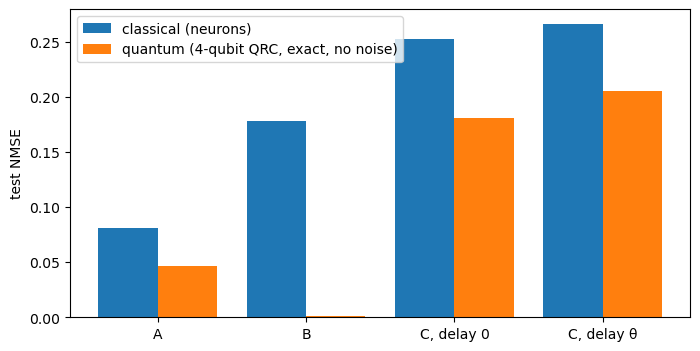

In [17]:
print(f"{'':12s} {'classical':>10s} {'4q QRC':>10s}   (test NMSE: 0 perfect, 1 chance)")
for name, (cl, qu) in scores.items():
    print(f"{name:12s} {cl:10.3f} {qu:10.3f}")

names = list(scores)
x = np.arange(len(names))
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, [scores[k][0] for k in names], 0.4, label="classical (neurons)")
plt.bar(x + 0.2, [scores[k][1] for k in names], 0.4, label="quantum (4-qubit QRC, exact, no noise)")
plt.xticks(x, names)
plt.ylabel("test NMSE")
plt.legend()
plt.show()